# Explainable AI for 30-Day Hospital Readmission Prediction

## Objective

This notebook explains the predictions produced by the selected
XGBoost readmission model.

SHAP (SHapley Additive exPlanations) is used to examine:

1. Global model behavior
2. Overall feature importance
3. Direction of feature contributions
4. Individual encounter predictions

The purpose is to make the machine-learning component of the platform
more transparent and interpretable.

SHAP values describe how model inputs contribute to a prediction.
They should not be interpreted as evidence that a feature causes
hospital readmission.

In [1]:
#Importing necessary libraries for model explainability

import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

MODEL_PATH = PROJECT_ROOT / "models" / "readmission_xgboost_v1.joblib"

print("Project root:", PROJECT_ROOT)
print("Model exists:", MODEL_PATH.exists())
print("SHAP version:", shap.__version__)

Project root: C:\Users\nolee\Adaptive Hospital Intelligence Platform
Model exists: True
SHAP version: 0.51.0


In [2]:
# Load the final trained model for explainability analysis

final_model = joblib.load(MODEL_PATH)

print(type(final_model))
print(final_model.named_steps.keys())

<class 'sklearn.pipeline.Pipeline'>
dict_keys(['preprocessor', 'classifier'])


In [3]:
# Display the final trained model for inspection

final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['age_midpoint','gender','race',...,'tertiary_diagnosis_category', 'total_previous_visits','has_previous_inpatient_visit']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'

In [4]:
# Display the steps of the final trained pipeline model

print("Pipeline steps:")

for name, step in final_model.named_steps.items():
    print(f"{name}: {type(step).__name__}")

Pipeline steps:
preprocessor: ColumnTransformer
classifier: XGBClassifier


In [5]:
# Extract the preprocessor and classifier from the final trained pipeline model

preprocessor = final_model.named_steps["preprocessor"]
xgb_model = final_model.named_steps["classifier"]

print("Preprocessor:", type(preprocessor).__name__)
print("Classifier:", type(xgb_model).__name__)

Preprocessor: ColumnTransformer
Classifier: XGBClassifier


In [6]:
#IMPORTING LIBRARIES
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

In [7]:
# Load clinical features dataset

DATA_PATH = Path("../data/processed/clinical_features.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 101,766
Columns: 29


,patient_id,encounter_id,age_midpoint,gender,race,admission_type,admission_source,discharge_disposition,length_of_stay,previous_inpatient_visits,previous_outpatient_visits,previous_emergency_visits,primary_diagnosis,secondary_diagnosis,tertiary_diagnosis,diagnosis_count,lab_procedure_count,procedure_count,medication_count,hba1c_result,glucose_result,insulin_status,diabetes_medication,readmitted_30_days,primary_diagnosis_category,secondary_diagnosis_category,tertiary_diagnosis_category,total_previous_visits,has_previous_inpatient_visit
0,8222157,2278392,5,Female,Caucasian,Unmapped:6,Physician Referral,Not Mapped,1,0,0,0,250.83,NaN,NaN,1,41,0,1,NaN,NaN,No,No,False,Diabetes,Other,Other,0,0
1,55629189,149190,15,Female,Caucasian,Emergency,Emergency Room,Discharged to home,3,0,0,0,276,250.01,255,9,59,0,18,NaN,NaN,Up,Yes,False,Endocrine,Diabetes,Endocrine,0,0
2,86047875,64410,25,Female,AfricanAmerican,Emergency,Emergency Room,Discharged to home,2,1,2,0,648,250,V27,6,11,5,13,NaN,NaN,No,Yes,False,Pregnancy,Diabetes,Supplementary,3,1
3,82442376,500364,35,Male,Caucasian,Emergency,Emergency Room,Discharged to home,2,0,0,0,8,250.43,403,7,44,1,16,NaN,NaN,Up,Yes,False,Infectious,Diabetes,Circulatory,0,0
4,42519267,16680,45,Male,Caucasian,Emergency,Emergency Room,Discharged to home,1,0,0,0,197,157,250,5,51,0,8,NaN,NaN,Steady,Yes,False,Neoplasms,Neoplasms,Diabetes,0,0


In [8]:
# Target variable distribution

TARGET = "readmitted_30_days"

print("Target distribution:")
print(df[TARGET].value_counts())

print("\nTarget distribution (%):")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
readmitted_30_days
False    90409
True     11357
Name: count, dtype: int64

Target distribution (%):
readmitted_30_days
False    88.84
True     11.16
Name: proportion, dtype: float64


In [9]:
# Model feature selection

model_features = [
    "age_midpoint",
    "gender",
    "race",
    "admission_type",
    "admission_source",
    "discharge_disposition",
    "length_of_stay",
    "previous_inpatient_visits",
    "previous_outpatient_visits",
    "previous_emergency_visits",
    "diagnosis_count",
    "lab_procedure_count",
    "procedure_count",
    "medication_count",
    "hba1c_result",
    "glucose_result",
    "insulin_status",
    "diabetes_medication",
    "primary_diagnosis_category",
    "secondary_diagnosis_category",
    "tertiary_diagnosis_category",
    "total_previous_visits",
    "has_previous_inpatient_visit",
]

X = df[model_features].copy()
y = df[TARGET].astype(int)
groups = df["patient_id"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique patients:", groups.nunique())

X shape: (101766, 23)
y shape: (101766,)
Unique patients: 71518


In [10]:
# Patient-level train/test split

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

print("Training encounters:", len(X_train))
print("Testing encounters:", len(X_test))

print("\nTraining patients:", train_groups.nunique())
print("Testing patients:", test_groups.nunique())

Training encounters: 81613
Testing encounters: 20153

Training patients: 57214
Testing patients: 14304


In [ ]:
# Test set statistics

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Test positives:", y_test.sum())
print("Test positive rate:", round(y_test.mean(), 4))

X_test shape: (20153, 23)
y_test shape: (20153,)
Test positives: 2151
Test positive rate: 0.1067


In [12]:
# Transformed feature names

feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 30 transformed features:")

for feature in feature_names[:30]:
    print(feature)

Number of transformed features: 141

First 30 transformed features:
num__age_midpoint
num__length_of_stay
num__previous_inpatient_visits
num__previous_outpatient_visits
num__previous_emergency_visits
num__diagnosis_count
num__lab_procedure_count
num__procedure_count
num__medication_count
num__total_previous_visits
num__has_previous_inpatient_visit
cat__gender_Female
cat__gender_Male
cat__gender_Unknown/Invalid
cat__race_AfricanAmerican
cat__race_Asian
cat__race_Caucasian
cat__race_Hispanic
cat__race_Other
cat__admission_type_Elective
cat__admission_type_Emergency
cat__admission_type_Newborn
cat__admission_type_Not Available
cat__admission_type_Not Mapped
cat__admission_type_Trauma Center
cat__admission_type_Unmapped:6
cat__admission_type_Urgent
cat__admission_source_Clinic Referral
cat__admission_source_Court/Law Enforcement
cat__admission_source_Emergency Room


In [13]:
# SHAP sample selection and transformation

SHAP_SAMPLE_SIZE = min(2000, len(X_test))

X_shap = X_test.sample(
    n=SHAP_SAMPLE_SIZE,
    random_state=42
)

X_shap_transformed = preprocessor.transform(X_shap)

print("Original shape:")
print(X_shap.shape)

print("\nTransformed shape:")
print(X_shap_transformed.shape)

print("\nNumber of feature names:")
print(len(feature_names))

Original shape:
(2000, 23)

Transformed shape:
(2000, 141)

Number of feature names:
141


In [14]:
# Verify that the number of transformed features matches the number of feature names

assert X_shap_transformed.shape[1] == len(feature_names)

print("✓ Feature names correctly match transformed model inputs.")

✓ Feature names correctly match transformed model inputs.


In [15]:
# SHAP value computation for the selected sample

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer(X_shap_transformed)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (2000, 141)


c:\Users\nolee\Adaptive Hospital Intelligence Platform\.venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


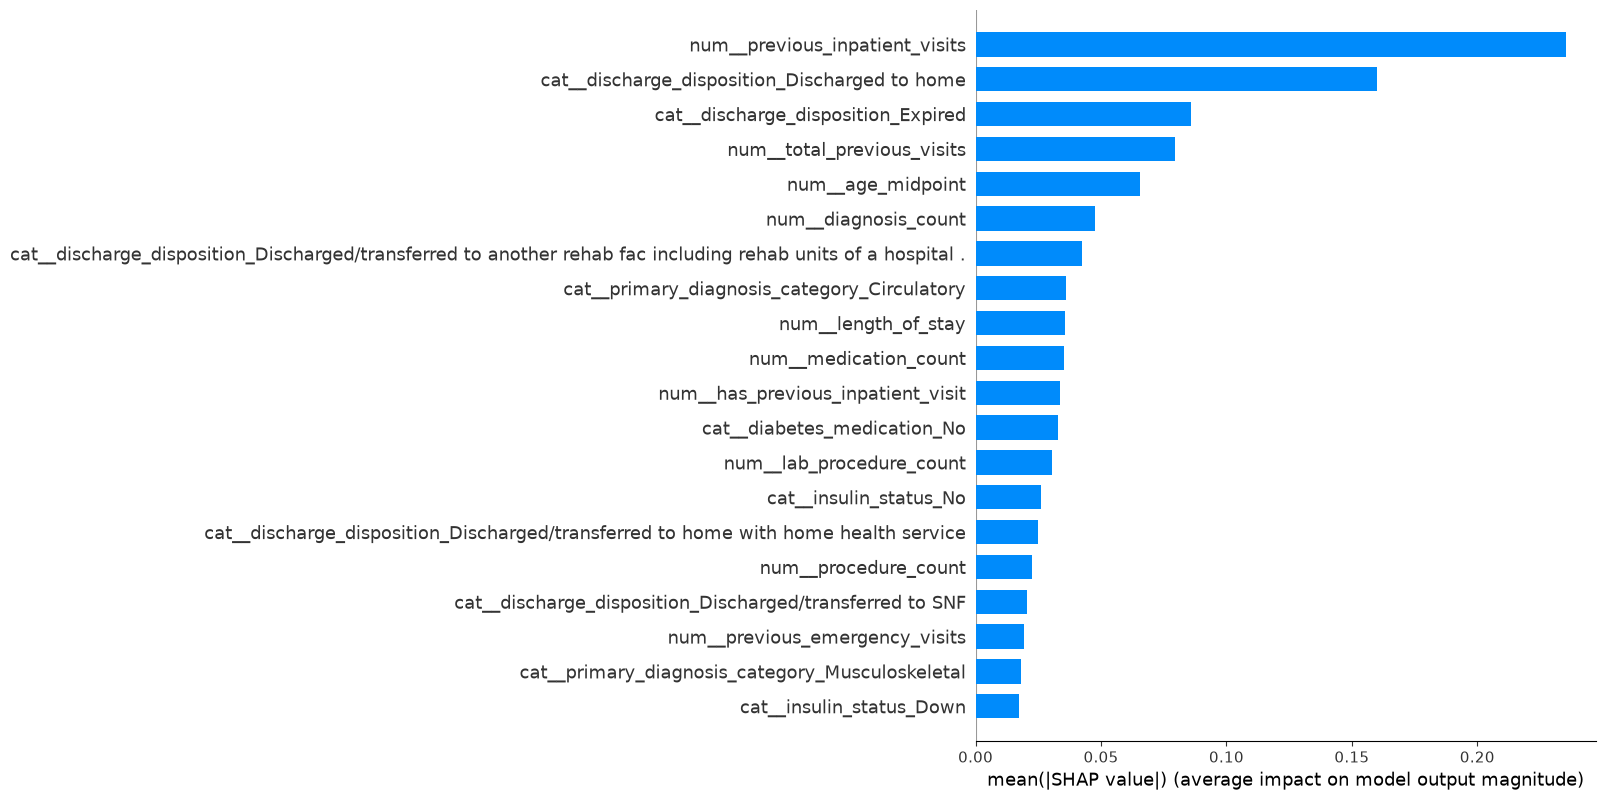

In [16]:
# SHAP summary plot for the selected sample...Global SHAP importance

shap.summary_plot(
    shap_values.values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20
)

c:\Users\nolee\Adaptive Hospital Intelligence Platform\.venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


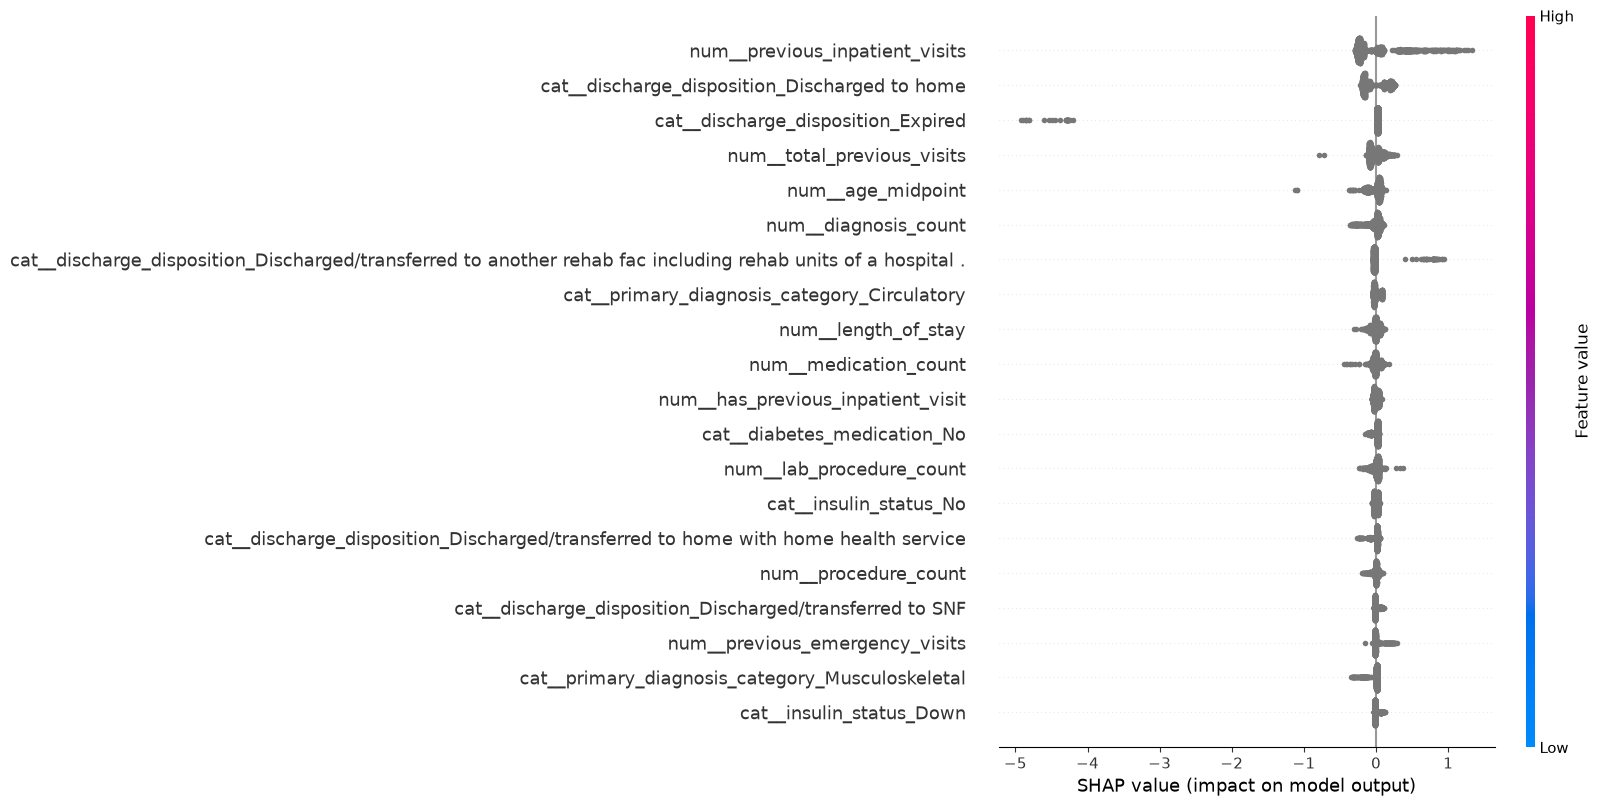

In [17]:
# SHAP beeswarm plot for the selected sample

shap.summary_plot(
    shap_values.values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20
)

## Individual Encounter Explanation

Global SHAP analysis identifies features that influence model predictions
across the population.

This section examines individual encounters to understand which model
features push a specific prediction toward higher or lower predicted
30-day readmission risk.

SHAP values describe the behavior of the trained model and should not be
interpreted as causal clinical effects.

In [18]:
# Generate probabilities for the SHAP sample using the complete pipeline

sample_probabilities = final_model.predict_proba(X_shap)[:, 1]

risk_results = pd.DataFrame({
    "predicted_probability": sample_probabilities
}, index=X_shap.index)

risk_results = risk_results.sort_values(
    "predicted_probability",
    ascending=False
)

risk_results.head(10)

,predicted_probability
79328,0.883277
42123,0.882260
28151,0.863393
94210,0.843339
77271,0.834471
55324,0.834274
48013,0.833437
74032,0.831470
84221,0.829736
56106,0.828603


In [19]:
# Select the encounter with the highest predicted probability and display its details

selected_index = risk_results.index[0]

selected_probability = risk_results.loc[
    selected_index,
    "predicted_probability"
]

print("Selected encounter index:", selected_index)
print(
    "Model score:",
    round(selected_probability, 4)
)
print(
    "Model score (%):",
    round(selected_probability * 100, 2)
)

Selected encounter index: 79328
Model score: 0.8833
Model score (%): 88.33


In [20]:
# Determine the position of the selected encounter within the SHAP sample

selected_position = X_shap.index.get_loc(selected_index)

print("Position in SHAP sample:", selected_position)

Position in SHAP sample: 1544


In [24]:
# Create a SHAP explanation object for the selected patient

import numpy as np

# Find the selected encounter's position in the SHAP sample
selected_position = X_shap.index.get_loc(selected_index)

# Convert only this encounter's transformed features to a 1D array
patient_data = X_shap_transformed[selected_position]

if hasattr(patient_data, "toarray"):
    patient_data = patient_data.toarray()

patient_data = np.asarray(patient_data).ravel()

# Build the individual SHAP explanation
patient_explanation = shap.Explanation(
    values=shap_values.values[selected_position],
    base_values=shap_values.base_values[selected_position],
    data=patient_data,
    feature_names=list(feature_names)
)

print("SHAP values:", patient_explanation.values.shape)
print("Feature values:", patient_explanation.data.shape)
print("Feature names:", len(patient_explanation.feature_names))


SHAP values: (141,)
Feature values: (141,)
Feature names: 141


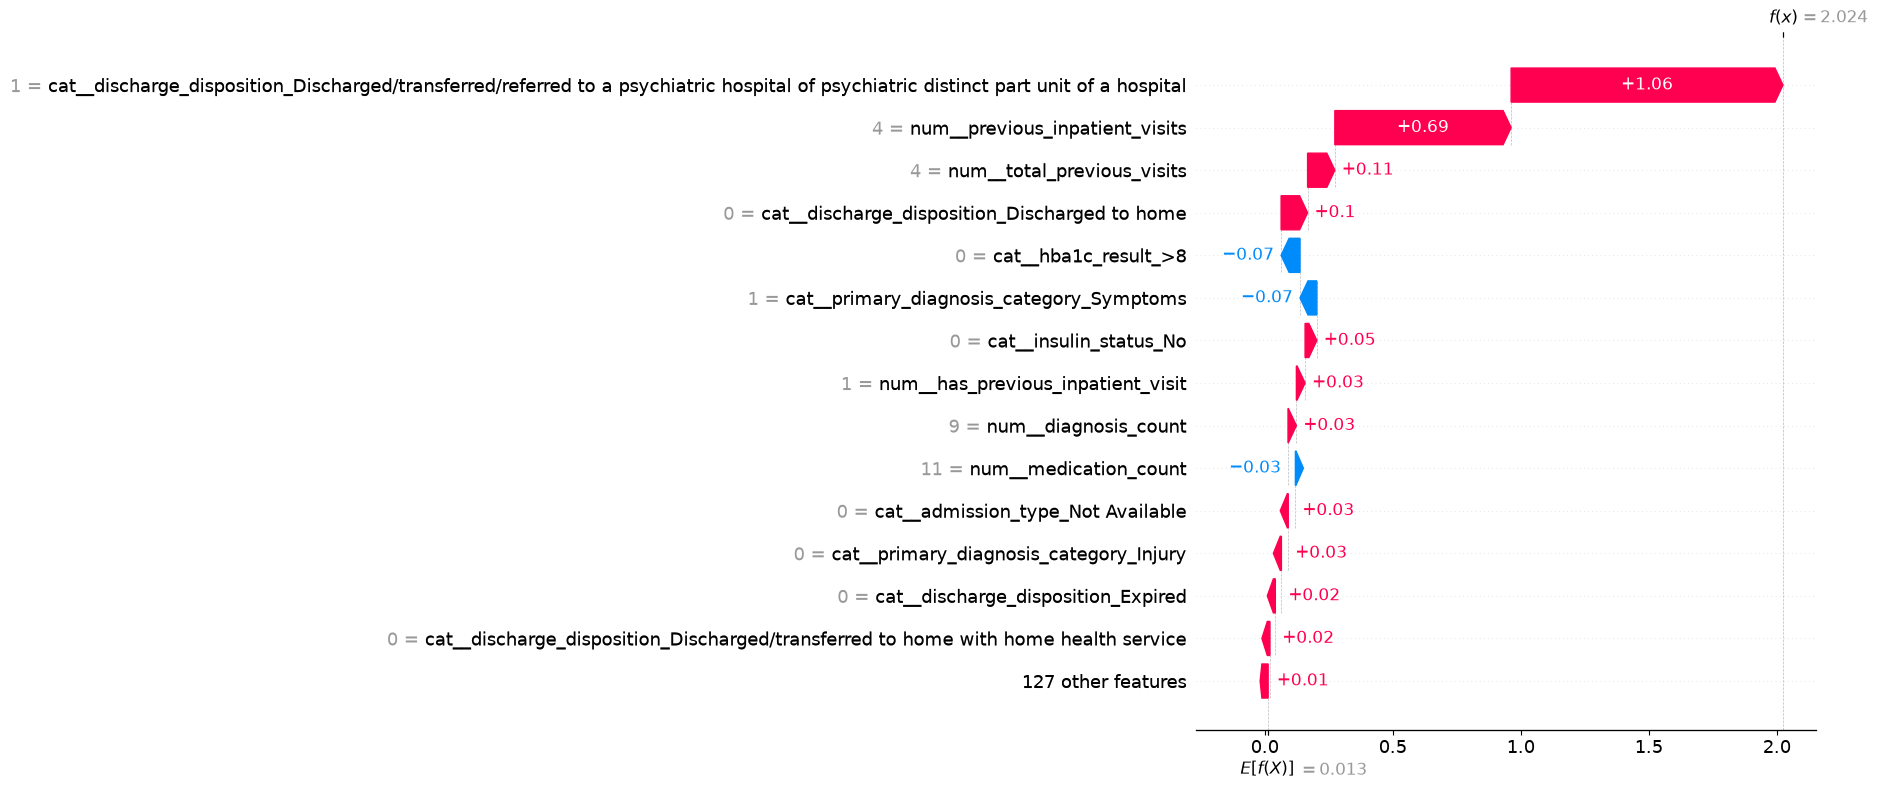

In [25]:
# Display a SHAP waterfall plot for the selected patient

shap.plots.waterfall(
    patient_explanation,
    max_display=15
)

In [26]:
# Verify that the individual SHAP explanation aligns with the feature names

assert len(patient_explanation.values) == len(feature_names)
assert len(patient_explanation.data) == len(feature_names)

print("Individual SHAP explanation is correctly aligned.")

Individual SHAP explanation is correctly aligned.


In [27]:
# Create a DataFrame for the selected patient's SHAP values and sort by absolute impact

patient_shap_df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": shap_values.values[selected_position]
})

patient_shap_df["abs_shap"] = (
    patient_shap_df["shap_value"].abs()
)

patient_shap_df = patient_shap_df.sort_values(
    "abs_shap",
    ascending=False
)

patient_shap_df.head(15)

,feature,shap_value,abs_shap
58,cat__discharge_disposition_Discharged/transfer...,1.061694,1.061694
2,num__previous_inpatient_visits,0.688500,0.688500
9,num__total_previous_visits,0.106437,0.106437
45,cat__discharge_disposition_Discharged to home,0.103398,0.103398
71,cat__hba1c_result_>8,-0.073763,0.073763
100,cat__primary_diagnosis_category_Symptoms,-0.065846,0.065846
77,cat__insulin_status_No,0.045986,0.045986
10,num__has_previous_inpatient_visit,0.033970,0.033970
5,num__diagnosis_count,0.032678,0.032678
8,num__medication_count,-0.028796,0.028796


In [30]:
# Identify and display the top model factors pushing the output higher and lower for the selected patient

risk_increasing = (
    patient_shap_df[
        patient_shap_df["shap_value"] > 0
    ]
    .sort_values("shap_value", ascending=False)
    .head(5)
)

risk_decreasing = (
    patient_shap_df[
        patient_shap_df["shap_value"] < 0
    ]
    .sort_values("shap_value")
    .head(5)
)

print("TOP MODEL FACTORS PUSHING OUTPUT HIGHER")
display(
    risk_increasing[
        ["feature", "shap_value"]
    ]
)

print("\nTOP MODEL FACTORS PUSHING OUTPUT LOWER")
display(
    risk_decreasing[
        ["feature", "shap_value"]
    ]
)

TOP MODEL FACTORS PUSHING OUTPUT HIGHER


,feature,shap_value
58,cat__discharge_disposition_Discharged/transfer...,1.061694
2,num__previous_inpatient_visits,0.688500
9,num__total_previous_visits,0.106437
45,cat__discharge_disposition_Discharged to home,0.103398
77,cat__insulin_status_No,0.045986



TOP MODEL FACTORS PUSHING OUTPUT LOWER


,feature,shap_value
71,cat__hba1c_result_>8,-0.073763
100,cat__primary_diagnosis_category_Symptoms,-0.065846
8,num__medication_count,-0.028796
51,cat__discharge_disposition_Discharged/transfer...,-0.016962
83,cat__primary_diagnosis_category_Circulatory,-0.016369


In [ ]:
#Inspecting clinical records for the selected patient

patient_features = X_shap.loc[selected_index]

patient_features.to_frame(
    name="Value"
)

,Value
age_midpoint,75
gender,Male
race,Caucasian
admission_type,Elective
admission_source,Physician Referral
discharge_disposition,Discharged/transferred/referred to a psychiatr...
length_of_stay,3
previous_inpatient_visits,4
previous_outpatient_visits,0
previous_emergency_visits,0
